In [7]:
#step 0
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
import os
import cv2
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

tf.random.set_seed(42)
np.random.seed(42)

Num GPUs Available:  0


Total classes: ['.ipynb_checkpoints', 'daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Distribution: {'.ipynb_checkpoints': 0, 'daisy': 764, 'dandelion': 1052, 'rose': 784, 'sunflower': 733, 'tulip': 984}
Total images: 4317


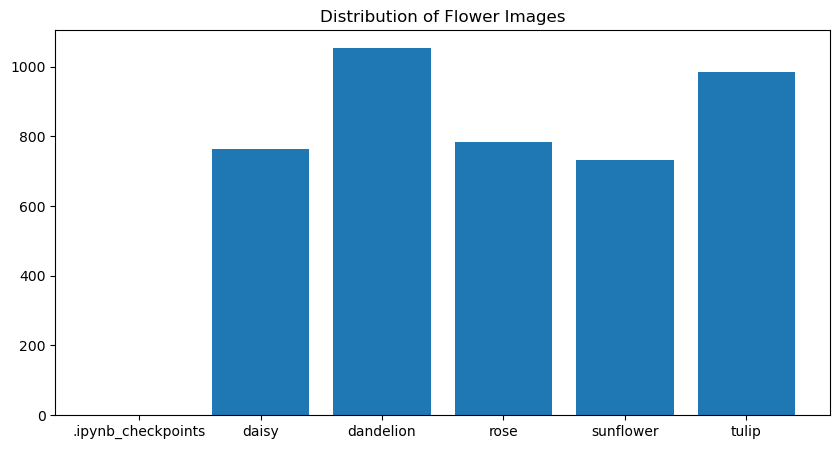

Average Height: 238.54, Average Width: 313.79


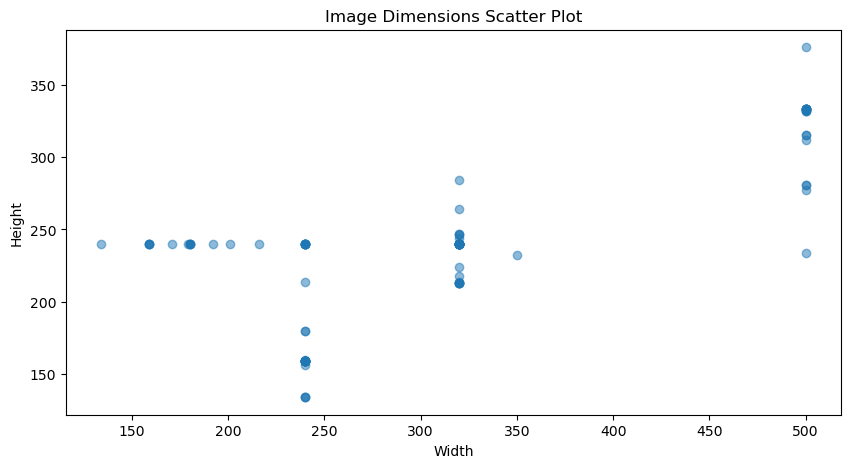

Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Classes found: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [8]:
#step 1
DATA_DIR = 'flowers'

# 1
class_names = sorted(os.listdir(DATA_DIR))
class_counts = {}

for c in class_names:
    class_path = os.path.join(DATA_DIR, c)
    if os.path.isdir(class_path):
        class_counts[c] = len(os.listdir(class_path))

print(f"Total classes: {class_names}")
print(f"Distribution: {class_counts}")
print(f"Total images: {sum(class_counts.values())}")

plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.title('Distribution of Flower Images')
plt.show()

# 2
heights = []
widths = []
sample_size = 100 

all_files = []
for root, dirs, files in os.walk(DATA_DIR):
    for file in files:
        if file.endswith(('jpg', 'jpeg', 'png')):
            all_files.append(os.path.join(root, file))


for img_path in np.random.choice(all_files, min(len(all_files), sample_size), replace=False):
    img = cv2.imread(img_path)
    if img is not None:
        h, w, _ = img.shape
        heights.append(h)
        widths.append(w)

print(f"Average Height: {np.mean(heights)}, Average Width: {np.mean(widths)}")
plt.figure(figsize=(10, 5))
plt.scatter(widths, heights, alpha=0.5)
plt.title('Image Dimensions Scatter Plot')
plt.xlabel('Width')
plt.ylabel('Height')
plt.show()

# 3
IMG_HEIGHT = 180
IMG_WIDTH = 180
BATCH_SIZE = 32


train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)


val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Classes found:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [9]:
#check flowers
import os

DATA_DIR = 'flowers'

if os.path.exists(DATA_DIR):
    print("✅we find")
    print("include：", os.listdir(DATA_DIR))
else:
    print("❌ not find")
    print("python：", os.getcwd())
    print("There are：", os.listdir(os.getcwd()))

✅we find
include： ['.ipynb_checkpoints', 'daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [10]:
# Step 2: Design CNN

def create_baseline_model():
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
        layers.Rescaling(1./255),
        
        # 1
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        
        # 2
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        
        # 3
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(5, activation='softmax')
    ])
    return model

model = create_baseline_model()

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,285 (15.22 MB)

 Trainable params: 3,989,285 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
#step 3 
# Hyperparameters: Learning Rate (Adam default is 0.001), Metrics (Accuracy)
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

# training
epochs = 15
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 101ms/step - accuracy: 0.4771 - loss: 1.2488 - val_accuracy: 0.5678 - val_loss: 1.0209
Epoch 2/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 18s 100ms/step - accuracy: 0.6323 - loss: 0.9521 - val_accuracy: 0.6014 - val_loss: 0.9802
Epoch 3/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 20s 99ms/step - accuracy: 0.6940 - loss: 0.7934 - val_accuracy: 0.6489 - val_loss: 0.8680
Epoch 4/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.7745 - loss: 0.5871 - val_accuracy: 0.6802 - val_loss: 0.8415
Epoch 5/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 20s 99ms/step - accuracy: 0.8677 - loss: 0.3738 - val_accuracy: 0.6211 - val_loss: 1.0693
Epoch 6/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 20s 95ms/step - accuracy: 0.9308 - loss: 0.2173 - val_accuracy: 0.6535 - val_loss: 1.1739
Epoch 7/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.9589 - loss: 0.1312 - val_accuracy: 0.6327 - val_loss: 1.4283
Epoch 8/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 20s 95ms/step - accuracy: 0.9794 - loss: 0.0777 

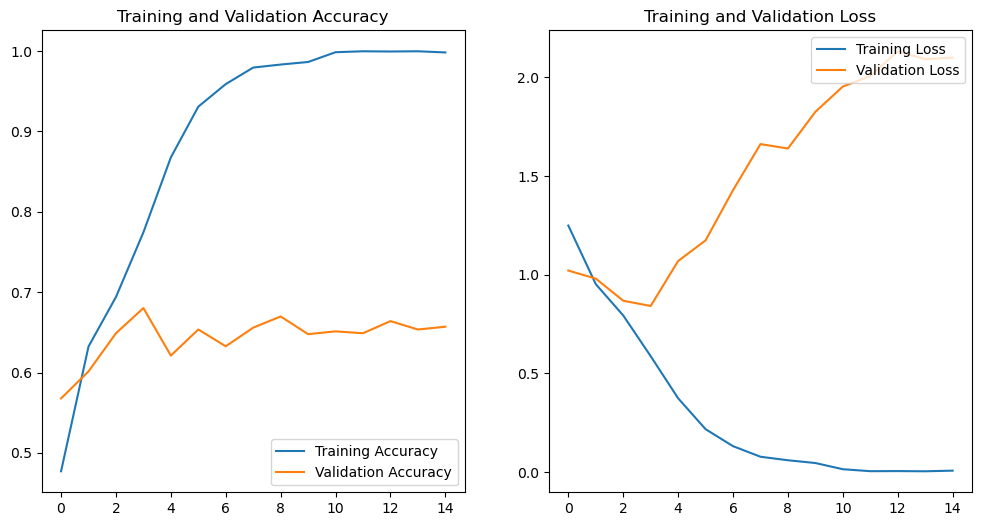

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━

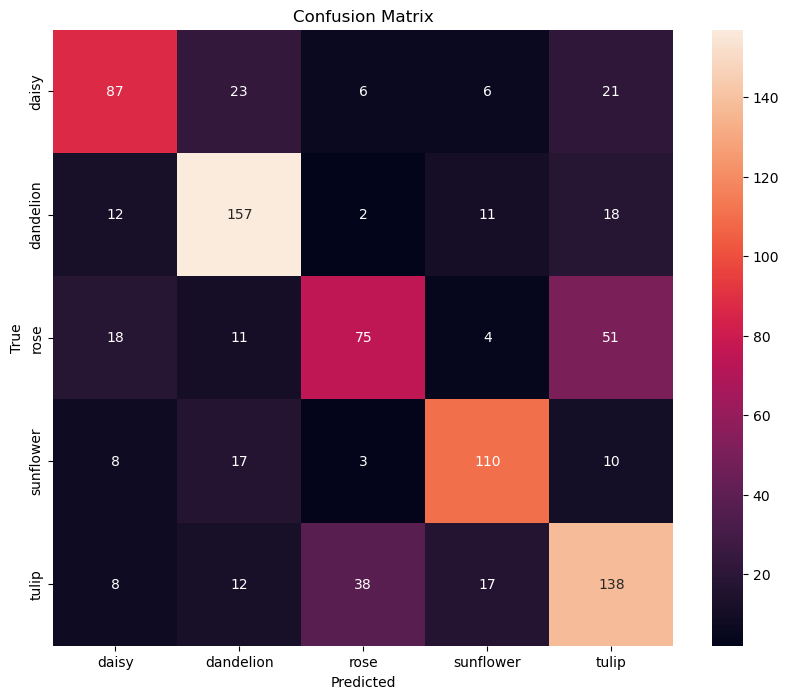

              precision    recall  f1-score   support

       daisy       0.65      0.61      0.63       143
   dandelion       0.71      0.79      0.75       200
        rose       0.60      0.47      0.53       159
   sunflower       0.74      0.74      0.74       148
       tulip       0.58      0.65      0.61       213

    accuracy                           0.66       863
   macro avg       0.66      0.65      0.65       863
weighted avg       0.66      0.66      0.65       863



In [12]:

#Step 5: Report the results
# 1. Accuracy &Loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

# 2. Confusion Matrix

y_true = []
y_pred = []

for images, labels in val_ds:
    y_true.extend(labels.numpy())
    predictions = model.predict(images)
    y_pred.extend(np.argmax(predictions, axis=1))


cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


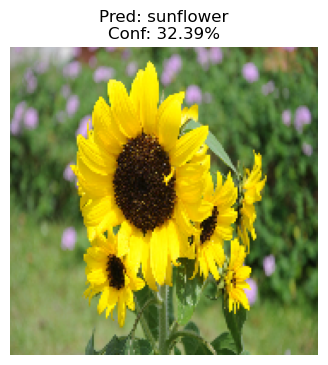

✅ It is: sunflower (: 32.39%)


In [13]:
# Step 6: Test with own phone picture
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing import image

my_image_name = 'test_flower.jpg' 
# -------------------------------

def predict_custom_image(img_path, model):
    try:
        # (180x180)
        img = image.load_img(img_path, target_size=(180, 180))
        
        img_array = image.img_to_array(img)
        img_array = tf.expand_dims(img_array, 0) # (1, 180, 180, 3)
        
        predictions = model.predict(img_array)
        score = tf.nn.softmax(predictions[0])
        
        # result
        predicted_class = class_names[np.argmax(score)]
        confidence = 100 * np.max(score)
        
        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Pred: {predicted_class}\nConf: {confidence:.2f}%")
        plt.show()
        
        print(f"✅ It is: {predicted_class} (: {confidence:.2f}%)")
        
    except FileNotFoundError:
        print(f"❌ cant find: {img_path}")

predict_custom_image(my_image_name, model)

Training L2 Regularization Model...
Epoch 1/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - accuracy: 0.3955 - loss: 1.5488 - val_accuracy: 0.5388 - val_loss: 1.2508
Epoch 2/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 21s 104ms/step - accuracy: 0.5837 - loss: 1.1783 - val_accuracy: 0.6246 - val_loss: 1.0930
Epoch 3/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 20s 97ms/step - accuracy: 0.6364 - loss: 1.0678 - val_accuracy: 0.6165 - val_loss: 1.0863
Epoch 4/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - accuracy: 0.6789 - loss: 0.9661 - val_accuracy: 0.6454 - val_loss: 1.0457
Epoch 5/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 11s 100ms/step - accuracy: 0.7157 - loss: 0.9049 - val_accuracy: 0.5956 - val_loss: 1.1236
Epoch 6/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 21s 100ms/step - accuracy: 0.7484 - loss: 0.8295 - val_accuracy: 0.6605 - val_loss: 1.0875
Epoch 7/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 20s 97ms/step - accuracy: 0.7933 - loss: 0.7539 - val_accuracy: 0.6454 - val_loss: 1.1523
Epoch 8/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 11s 98ms/s

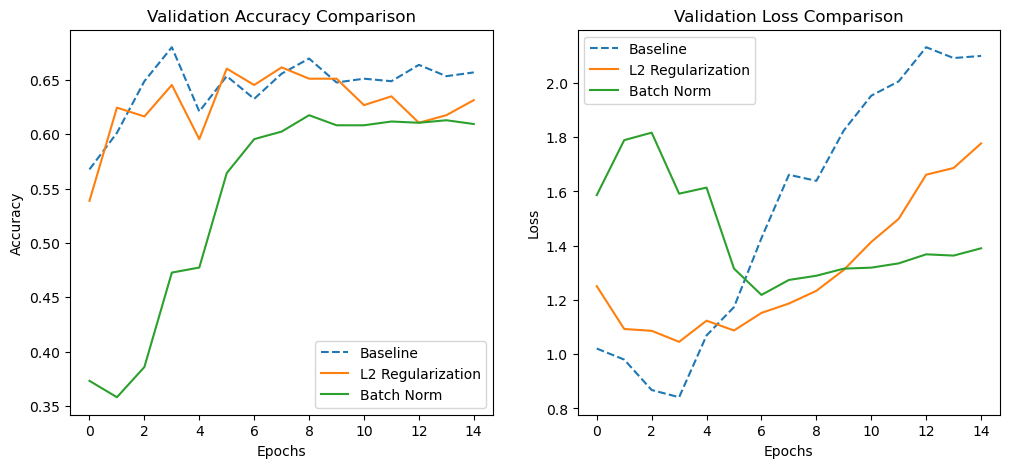

In [14]:
# Step 7: Regularization & Batch Normalization Implementation
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, regularizers

# --- Model A: Model with L2 Regularization (Prevents Overfitting) ---
def create_l2_model():
    model = models.Sequential([
        # Explicit Input Layer
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
        layers.Rescaling(1./255),
        
        # Add kernel_regularizer to Conv layers
        layers.Conv2D(16, 3, padding='same', activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.MaxPooling2D(),
        
        layers.Conv2D(32, 3, padding='same', activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.MaxPooling2D(),
        
        layers.Conv2D(64, 3, padding='same', activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.MaxPooling2D(),
        
        layers.Flatten(),
        # Add kernel_regularizer to Dense layer
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.Dense(5, activation='softmax')
    ])
    return model

# --- Model B: Model with Batch Normalization (Faster Convergence) ---
def create_bn_model():
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
        layers.Rescaling(1./255),
        
        # Conv -> BatchNormalization -> Activation -> Pooling
        # Note: use_bias=False is recommended because BN has its own bias
        layers.Conv2D(16, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(),
        
        layers.Conv2D(32, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(),
        
        layers.Flatten(),
        layers.Dense(128, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        
        layers.Dense(5, activation='softmax')
    ])
    return model

# 1. Train L2 Model
print("Training L2 Regularization Model...")
l2_model = create_l2_model()
l2_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
l2_history = l2_model.fit(train_ds, validation_data=val_ds, epochs=15, verbose=1)

# 2. Train Batch Norm Model
print("\nTraining Batch Normalization Model...")
bn_model = create_bn_model()
bn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
bn_history = bn_model.fit(train_ds, validation_data=val_ds, epochs=15, verbose=1)

# 3. Plot Comparison Results
plt.figure(figsize=(12, 5))

# Comparison of Validation Accuracy
plt.subplot(1, 2, 1)
# Check if baseline 'history' exists from Step 4
if 'history' in globals():
    plt.plot(history.history['val_accuracy'], label='Baseline', linestyle='--')
plt.plot(l2_history.history['val_accuracy'], label='L2 Regularization')
plt.plot(bn_history.history['val_accuracy'], label='Batch Norm')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Comparison of Validation Loss
plt.subplot(1, 2, 2)
if 'history' in globals():
    plt.plot(history.history['val_loss'], label='Baseline', linestyle='--')
plt.plot(l2_history.history['val_loss'], label='L2 Regularization')
plt.plot(bn_history.history['val_loss'], label='Batch Norm')
plt.title('Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

Training Improved Model (with Data Augmentation)...
Epoch 1/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 35s 304ms/step - accuracy: 0.3891 - loss: 1.4301 - val_accuracy: 0.5574 - val_loss: 1.1176
Epoch 2/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 33s 306ms/step - accuracy: 0.5620 - loss: 1.0805 - val_accuracy: 0.6083 - val_loss: 0.9715
Epoch 3/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 33s 305ms/step - accuracy: 0.6152 - loss: 0.9780 - val_accuracy: 0.6269 - val_loss: 0.9917
Epoch 4/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 41s 301ms/step - accuracy: 0.6314 - loss: 0.9370 - val_accuracy: 0.6744 - val_loss: 0.8485
Epoch 5/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 33s 303ms/step - accuracy: 0.6569 - loss: 0.8725 - val_accuracy: 0.6211 - val_loss: 0.9175
Epoch 6/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 41s 302ms/step - accuracy: 0.6818 - loss: 0.8338 - val_accuracy: 0.6825 - val_loss: 0.8388
Epoch 7/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 41s 301ms/step - accuracy: 0.6951 - loss: 0.8011 - val_accuracy: 0.7080 - val_loss: 0.7604
Epoch 8/25
108/108 ━━━━━━━━━━━━

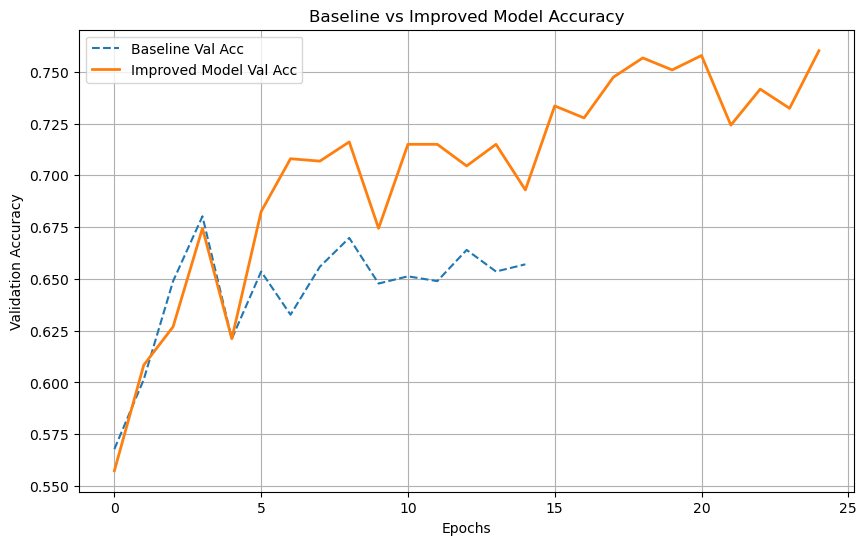

Final Validation Accuracy of Improved Model: 76.01%


In [15]:
# Step 8: Improvement Strategies (Data Augmentation + Dropout)

def create_improved_model():
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
        
        # --- Data Augmentation Layers (Active only during training) ---
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        
        layers.Rescaling(1./255),
        
        # Increased network depth and width
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        
        # Dropout Layer (Drops 20% of connections to prevent overfitting)
        layers.Dropout(0.2),
        
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        
        # Additional Dropout before output
        layers.Dropout(0.2),
        
        layers.Dense(5, activation='softmax')
    ])
    return model

print("Training Improved Model (with Data Augmentation)...")
# Note: Increased epochs to 25 because augmentation makes training harder but more robust
improved_model = create_improved_model()
improved_model.compile(optimizer='adam',
                       loss='sparse_categorical_crossentropy',
                       metrics=['accuracy'])

improved_history = improved_model.fit(train_ds, validation_data=val_ds, epochs=25, verbose=1)

# Plot Final Comparison
plt.figure(figsize=(10, 6))
if 'history' in globals():
    plt.plot(history.history['val_accuracy'], label='Baseline Val Acc', linestyle='--')
plt.plot(improved_history.history['val_accuracy'], label='Improved Model Val Acc', linewidth=2)
plt.title('Baseline vs Improved Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Print Final Accuracy
final_acc = improved_history.history['val_accuracy'][-1]
print(f"Final Validation Accuracy of Improved Model: {final_acc*100:.2f}%")